In [8]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

df = pd.read_csv('adult.csv')
df.replace('?', np.nan, inplace=True)
df_clean = df.dropna().reset_index(drop=True)
df_clean.to_csv('adult_cleaned.csv', index=False)

print("Before cleaning:", df.shape)
print("After cleaning:", df_clean.shape)
df = df_clean

Before cleaning: (32561, 15)
After cleaning: (30162, 15)


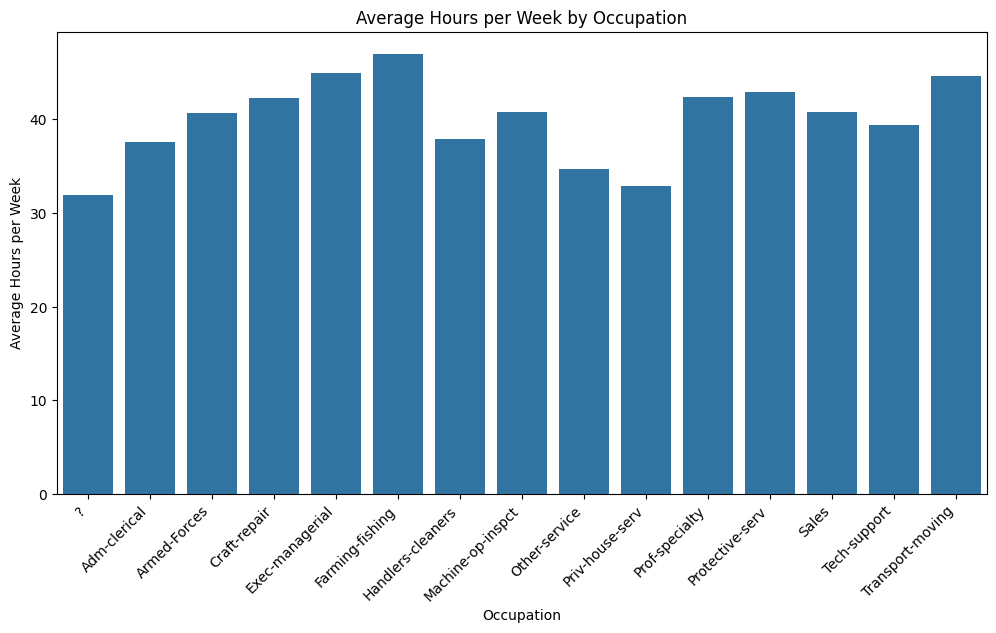

In [12]:
#Task 1
df = pd.read_csv("adult.csv")

avg_hours = df.groupby("occupation")["hours.per.week"].mean()

plt.figure(figsize=(12, 6))
sns.barplot(x=avg_hours.index, y=avg_hours.values)

plt.xlabel("Occupation")
plt.ylabel("Average Hours per Week")
plt.title("Average Hours per Week by Occupation")

plt.xticks(rotation=45, ha="right")

plt.show()

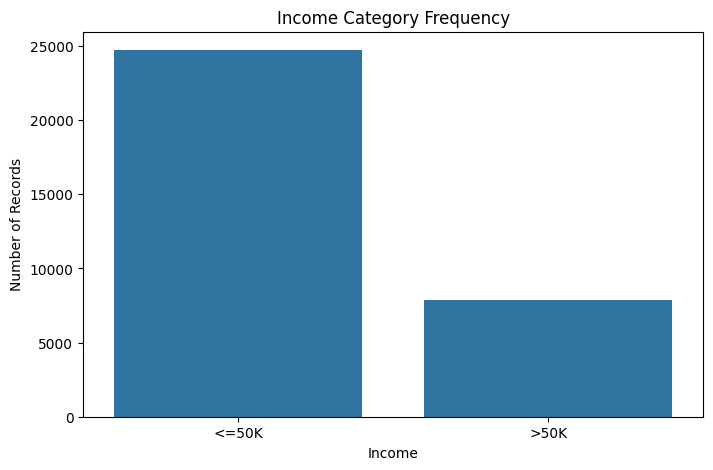

income
<=50K    24720
>50K      7841
Name: count, dtype: int64

In [15]:
#Task 2
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="income")

plt.xlabel("Income")
plt.ylabel("Number of Records")
plt.title("Income Category Frequency")

plt.show()
df["income"].value_counts()

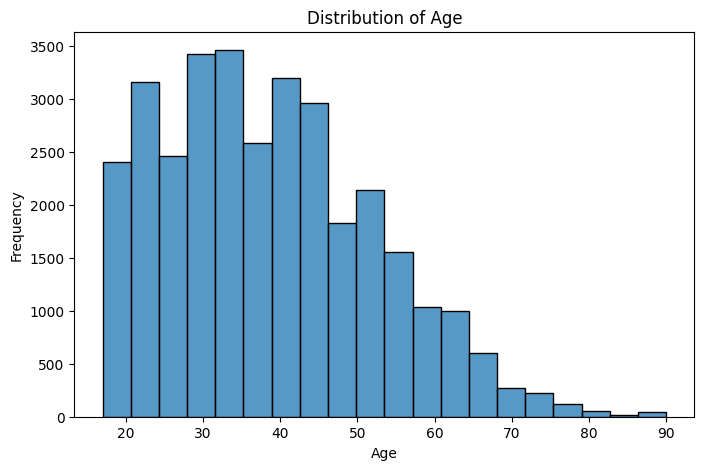

It is right skewed


In [17]:
#Task 3
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="age", bins=20)

plt.xlabel("Age")
plt.ylabel("Frequency")
plt.title("Distribution of Age")

plt.show()

print("It is right skewed")

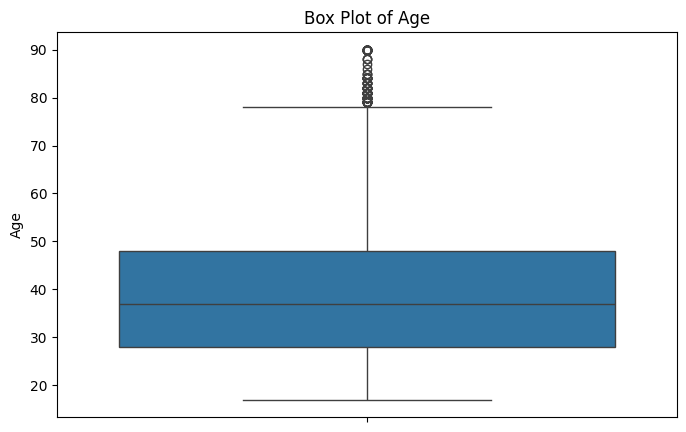

In [19]:
#Task 4
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, y="age")

plt.ylabel("Age")
plt.title("Box Plot of Age")

plt.show()

In [20]:
#Task 5
Q1 = df["age"].quantile(0.25)
Q3 = df["age"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df["age"] < lower) | (df["age"] > upper)]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower)
print("Upper Bound:", upper)
print("Number of Outliers:", len(outliers))

Q1: 28.0
Q3: 48.0
IQR: 20.0
Lower Bound: -2.0
Upper Bound: 78.0
Number of Outliers: 143


In [23]:
#Task 6
df["zscore"] = stats.zscore(df["age"])

outliers_z = df[df["zscore"].abs() > 3]

print("IQR Outliers:", len(outliers))
print("Z-score Outliers:", len(outliers_z))

# No, IQR and z-score do not flag the same number of outliers. 
# The IQR method identifies 143 outliers, while the z-score method identifies 121 outliers. 
# The age distribution is right-skewed rather than perfectly symmetric. 
# Since the z-score method works best for approximately normally distributed data and is 
# affected by the mean and standard deviation, it can produce a different number of outliers. 
# The IQR method is more robust to skewed distributions.

IQR Outliers: 143
Z-score Outliers: 121


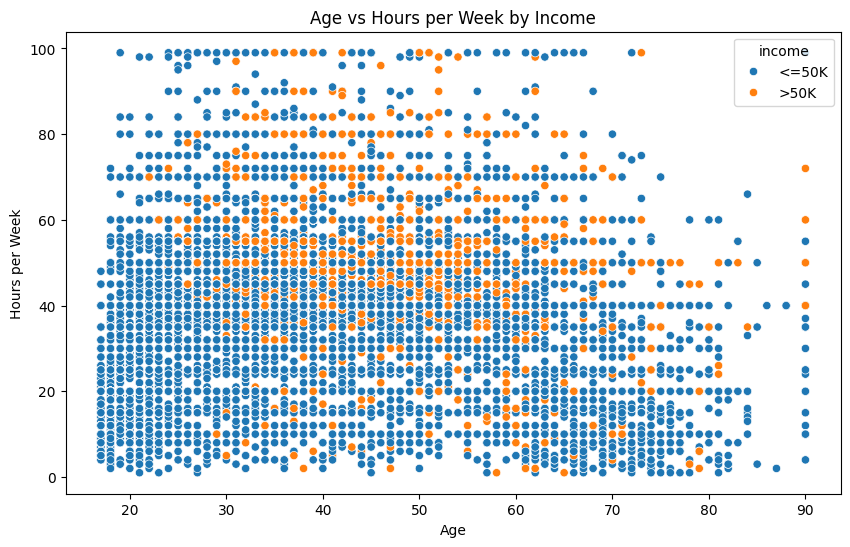

In [24]:
#Task 7
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="age",
    y="hours.per.week",
    hue="income"
)

plt.xlabel("Age")
plt.ylabel("Hours per Week")
plt.title("Age vs Hours per Week by Income")

plt.show()

In [27]:
#Task 8
avg_age = df.groupby("education.num")["age"].mean()
avg_age

education.num
1     42.764706
2     46.142857
3     42.885886
4     48.445820
5     41.060311
6     37.429796
7     32.355745
8     32.000000
9     38.974479
10    35.756275
11    38.553546
12    37.381443
13    38.904949
14    44.049913
15    44.746528
16    47.702179
Name: age, dtype: float64

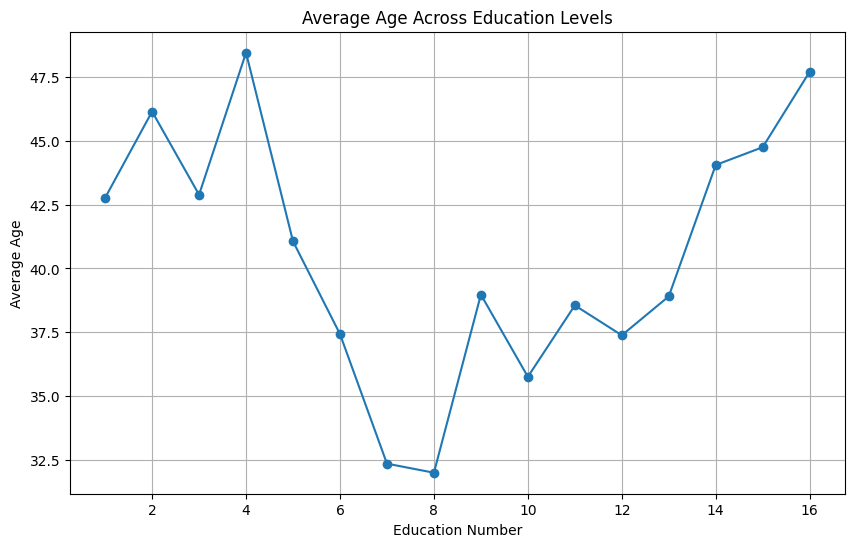

In [28]:
plt.figure(figsize=(10, 6))

plt.plot(avg_age.index, avg_age.values, marker="o")

plt.xlabel("Education Number")
plt.ylabel("Average Age")
plt.title("Average Age Across Education Levels")

plt.grid(True)
plt.show()

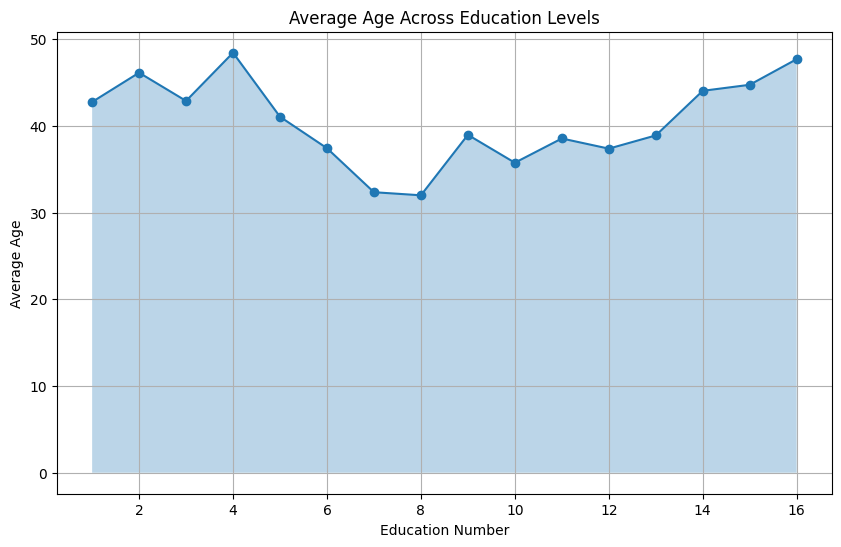

In [29]:
plt.figure(figsize=(10, 6))

plt.plot(avg_age.index, avg_age.values, marker="o")
plt.fill_between(avg_age.index, avg_age.values, alpha=0.3)

plt.xlabel("Education Number")
plt.ylabel("Average Age")
plt.title("Average Age Across Education Levels")

plt.grid(True)
plt.show()

# The line chart makes the trend easier to follow because the focus is on how the average age changes from one education level to the next.
# The area chart adds a filled region below the line, making the magnitude of the values more visually prominent. 
# However, the fill can make the chart look heavier and slightly reduce the clarity of small changes compared with the plain line chart.

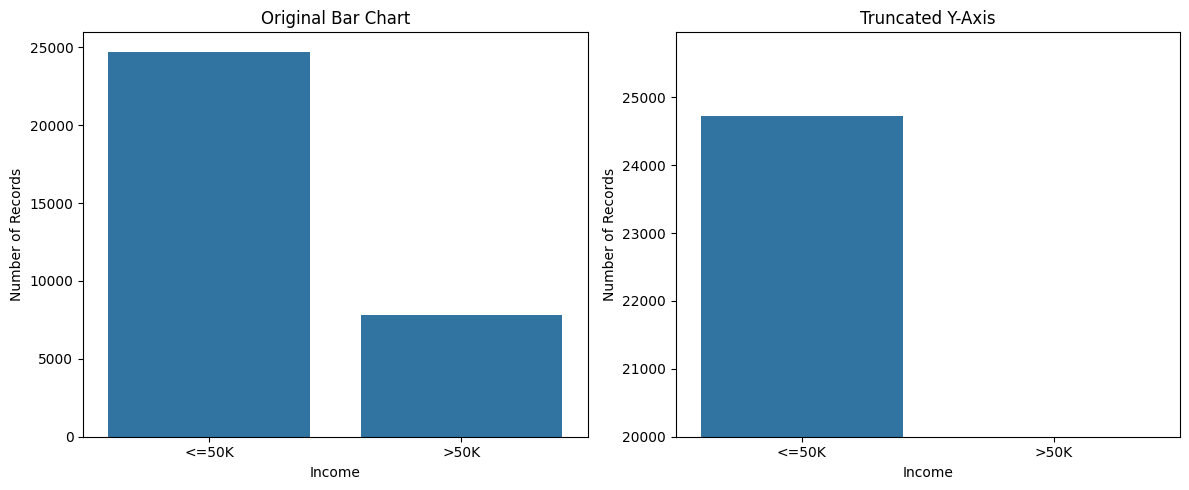

In [30]:
#Task 9
income_counts = df["income"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Original bar chart
sns.barplot(x=income_counts.index, y=income_counts.values, ax=axes[0])
axes[0].set_xlabel("Income")
axes[0].set_ylabel("Number of Records")
axes[0].set_title("Original Bar Chart")

# Truncated y-axis
sns.barplot(x=income_counts.index, y=income_counts.values, ax=axes[1])
axes[1].set_xlabel("Income")
axes[1].set_ylabel("Number of Records")
axes[1].set_title("Truncated Y-Axis")

# Deliberately start y-axis above zero
axes[1].set_ylim(bottom=20000)

plt.tight_layout()
plt.show()